In [78]:
import numpy as np
import matplotlib.pyplot as plt
import math

from scipy.integrate import solve_ivp

%load_ext autoreload
%autoreload 2

import physics

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [84]:
import importlib
importlib.reload(physics)

<module 'physics' from '/Users/peytaguo/PHYS2201/Solar Sail Computational Project/physics.py'>

## Gravitational Only

We first verify that with just the gravitational pull of the sun, at 1AU away and travelling at orbital velocity, the trajectory of the spacecraft forms a complete orbit in the course of a year.

Orbital speed: $$v = \sqrt{\frac{GM_{\odot}}{r}}$$
Orbital period: $$T = 2\pi \sqrt{\frac{r^3}{GM_{\odot}}}$$


In [69]:
physics.DT = 1
orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
year =  365.25 * 24 * 60 * 60

physics.position_vector = np.array([physics.AU, 0.0, 0.0])
physics.velocity_vector = np.array([0, 0, orbit_speed])

state = np.concatenate((physics.position_vector, physics.velocity_vector, [0.0]))

print("Orbital speed:", orbit_speed)
print("Initial state:", state)

Orbital speed: 29788.8993205065
Initial state: [1.49600000e+11 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 2.97888993e+04 0.00000000e+00]


In [ ]:
history = physics.integrate_justg(year)

In [ ]:
print(history[:5])

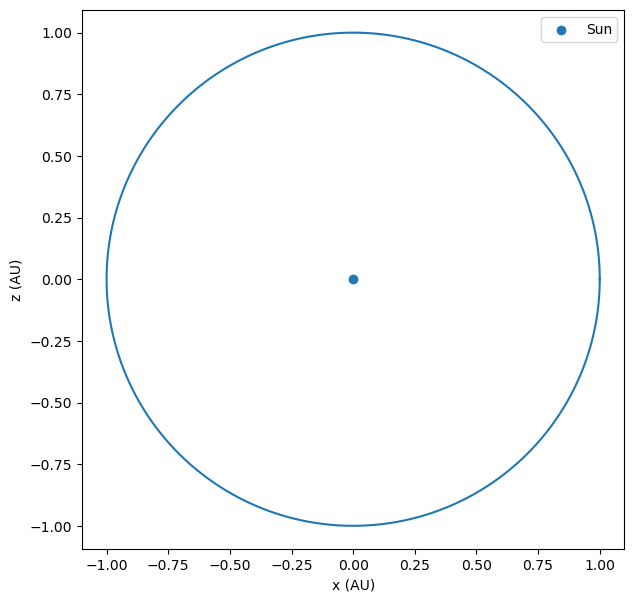

In [11]:
plt.figure(figsize=(7, 7))

plt.plot(
    history[:, 0] / physics.AU,
    history[:, 2] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("z (AU)")
plt.axis("equal")
plt.legend()
plt.show()

Here, we've changed DT to 1000 seconds, because intgration with DT set to 1 is not particularly computationally efficiency. 

Orbital speed: 29788.8993205065
Initial state: [1.49600000e+11 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 2.97888993e+04 0.00000000e+00]


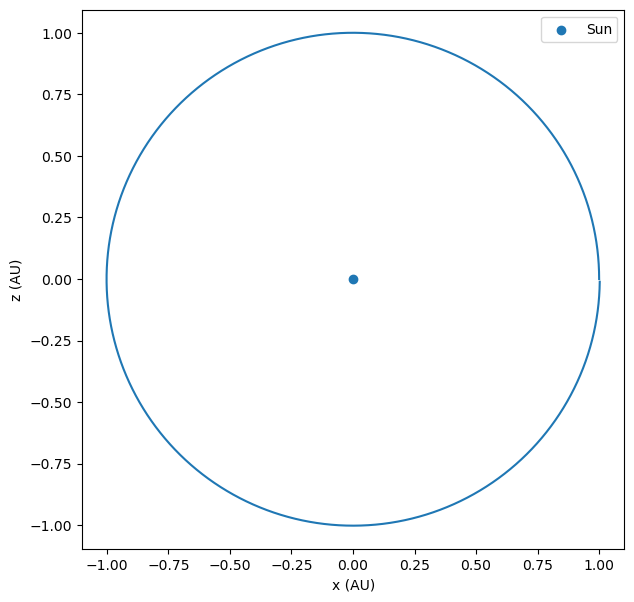

In [ ]:
physics.DT = 1000

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
year =  365.25 * 24 * 60 * 60

physics.position_vector = np.array([physics.AU, 0.0, 0.0])
physics.velocity_vector = np.array([0, 0, orbit_speed])

state = np.concatenate((physics.position_vector, physics.velocity_vector, [0.0]))

print("Orbital speed:", orbit_speed)
print("Initial state:", state)

history_1000 = physics.integrate_justg(year)

plt.figure(figsize=(7, 7))

plt.plot(
    history_1000[:, 0] / physics.AU,
    history_1000[:, 2] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("z (AU)")
plt.axis("equal")
plt.legend()
plt.show()

To check the error from integration, we can verify in two ways: 
1. check the error in the first and last entry of the integration of the orbtial period,
2. Verify that total energy is constant, ie 
$$
E_{total} = \frac{1}{2}\mathbf{v}\cdot\mathbf{v} - \frac{GM_{\odot}}{r} \text{ is constant.} 
$$

In [ ]:
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5
physics.DT = 1
physics.position_vector = np.array([physics.AU, 0.0, 0.0])
physics.velocity_vector = np.array([0, 0, orbit_speed])

state = np.concatenate((physics.position_vector, physics.velocity_vector, [0.0]))

history_orbital_period_dt1 = physics.integrate_justg(orbital_period)


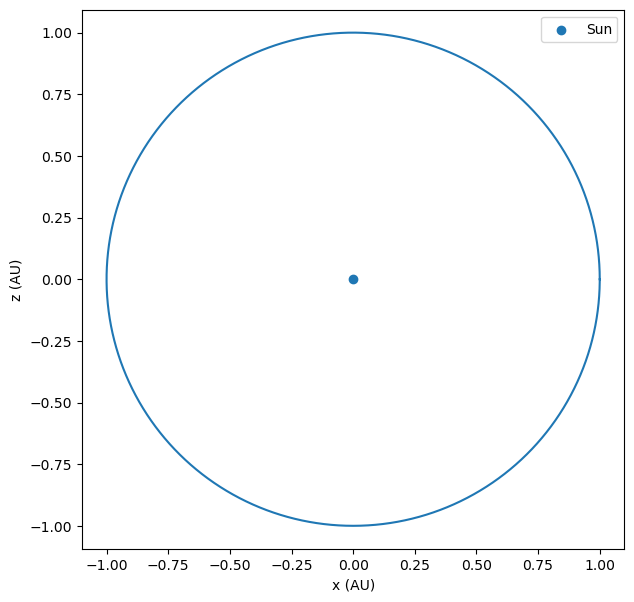

In [9]:
plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt1[:, 0] / physics.AU,
    history_orbital_period_dt1[:, 2] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("z (AU)")
plt.axis("equal")
plt.legend()
plt.show()

In [30]:
# method 1 evaluation
initial_op1 = history_orbital_period_dt1[0]
final_op1 = history_orbital_period_dt1[-1]

pos_diff_op1 = np.linalg.norm(final_op1[:3] - initial_op1[:3])

vel_diff_op1 = np.linalg.norm(final_op1[3:-1] - initial_op1[3:-1]) 

print("position_difference relative to 1 AU: {}".format(pos_diff_op1/physics.AU))
print("velocity difference: {}".format(vel_diff_op1))

position_difference relative to 1 AU: 1.2005020263039918e-05
velocity difference: 0.3517411751605749


(array([-5.0e-07,  0.0e+00,  5.0e-07,  1.0e-06,  1.5e-06,  2.0e-06,
         2.5e-06,  3.0e-06]),
 [Text(0, -5e-07, '−0.5'),
  Text(0, 0.0, '0.0'),
  Text(0, 5e-07, '0.5'),
  Text(0, 1.0000000000000002e-06, '1.0'),
  Text(0, 1.5e-06, '1.5'),
  Text(0, 2e-06, '2.0'),
  Text(0, 2.5e-06, '2.5'),
  Text(0, 3e-06, '3.0')])

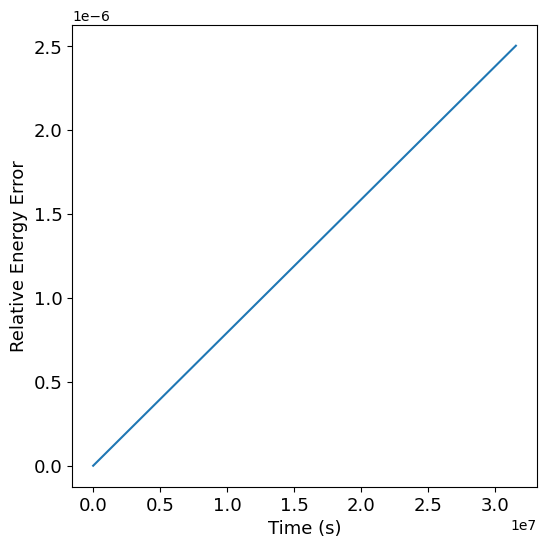

In [36]:
# method 2 evaluation 

position_op1 = history_orbital_period_dt1[:, :3]
velocity_op1 = history_orbital_period_dt1[:, 3:6]

magnitude_position_op1 = np.linalg.norm(position_op1, axis=1)
velocity_squared_op1 = np.sum(velocity_op1**2, axis=1)

total_energy = 0.5*velocity_squared_op1 - physics.GRAVITATIONAL * physics.SUN_MASS / magnitude_position_op1

plt.figure(figsize=(6,6))

plt.plot(
    history_orbital_period_dt1[:,-1],
    (total_energy - total_energy[0]) / np.linalg.norm(total_energy[0])
)

plt.xlabel("Time (s)", fontsize = 13)
plt.ylabel("Relative Energy Error", fontsize = 13)
plt.xticks(fontsize = 13)
plt.yticks(fontsize = 13) 

In [37]:
maximum_rel_error = (total_energy[-1] - total_energy[0])/np.linalg.norm(total_energy[0])
print("maximum relative energy error: {}".format(maximum_rel_error))

maximum relative energy error: 2.5022479062319065e-06


Try for dt = 10, 100, 1000

dt=10

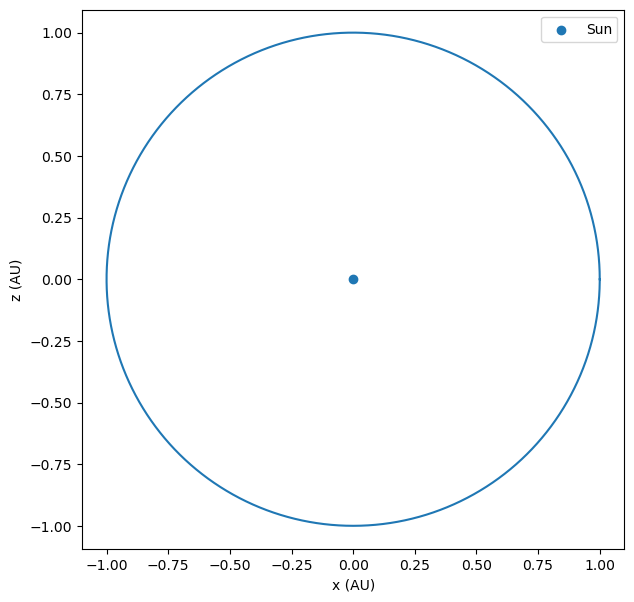

In [ ]:
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.DT = 10

physics.position_vector = np.array([physics.AU, 0.0, 0.0])
physics.velocity_vector = np.array([0, 0, orbit_speed])

state = np.concatenate((physics.position_vector, physics.velocity_vector, [0.0]))

history_orbital_period_dt10 = physics.integrate_justg(orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt10[:, 0] / physics.AU,
    history_orbital_period_dt10[:, 2] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("z (AU)")
plt.axis("equal")
plt.legend()
plt.show()

In [58]:
# method 1 evaluation
initial_op10 = history_orbital_period_dt10[0]
final_op10 = history_orbital_period_dt10[-1]

pos_diff_op10 = np.linalg.norm(final_op10[:3] - initial_op10[:3])

vel_diff_op10 = np.linalg.norm(final_op10[3:-1] - initial_op10[3:-1]) 

print("position_difference relative to 1 AU: {}".format(pos_diff_op10/physics.AU))
print("velocity difference: {}".format(vel_diff_op10))

position_difference relative to 1 AU: 0.00012010113361839588
velocity difference: 3.5188918522861585


(array([-5.0e-06,  0.0e+00,  5.0e-06,  1.0e-05,  1.5e-05,  2.0e-05,
         2.5e-05,  3.0e-05]),
 [Text(0, -4.9999999999999996e-06, '−0.5'),
  Text(0, 0.0, '0.0'),
  Text(0, 4.9999999999999996e-06, '0.5'),
  Text(0, 9.999999999999999e-06, '1.0'),
  Text(0, 1.4999999999999999e-05, '1.5'),
  Text(0, 1.9999999999999998e-05, '2.0'),
  Text(0, 2.4999999999999998e-05, '2.5'),
  Text(0, 2.9999999999999997e-05, '3.0')])

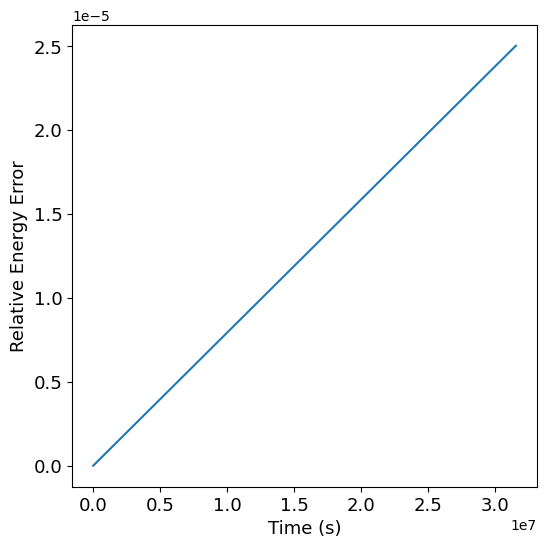

In [59]:
# method 2 evaluation 

position_op10 = history_orbital_period_dt10[:, :3]
velocity_op10 = history_orbital_period_dt10[:, 3:6]

magnitude_position_op10 = np.linalg.norm(position_op10, axis=1)
velocity_squared_op10 = np.sum(velocity_op10**2, axis=1)

total_energy_10 = 0.5*velocity_squared_op10 - physics.GRAVITATIONAL * physics.SUN_MASS / magnitude_position_op10

plt.figure(figsize=(6,6))

plt.plot(
    history_orbital_period_dt10[:,-1],
    (total_energy_10 - total_energy_10[0]) / np.linalg.norm(total_energy_10[0])
)

plt.xlabel("Time (s)", fontsize = 13)
plt.ylabel("Relative Energy Error", fontsize = 13)
plt.xticks(fontsize = 13)
plt.yticks(fontsize = 13) 

In [60]:
maximum_rel_error_10 = (total_energy_10[-1] - total_energy_10[0])/np.linalg.norm(total_energy_10[0])
print("maximum relative energy error: {}".format(maximum_rel_error_10))

maximum relative energy error: 2.5021366531288763e-05


dt=100

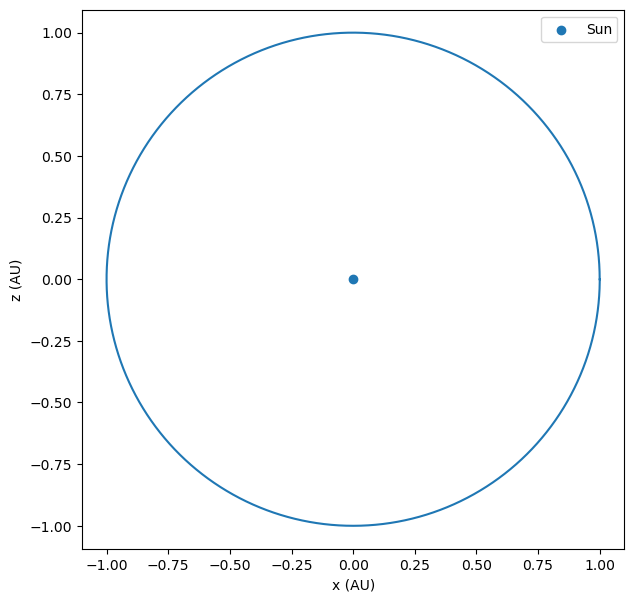

In [ ]:
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.DT = 100

physics.position_vector = np.array([physics.AU, 0.0, 0.0])
physics.velocity_vector = np.array([0, 0, orbit_speed])

state = np.concatenate((physics.position_vector, physics.velocity_vector, [0.0]))

history_orbital_period_dt100 = physics.integrate_justg(orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt100[:, 0] / physics.AU,
    history_orbital_period_dt100[:, 2] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("z (AU)")
plt.axis("equal")
plt.legend()
plt.show()

In [51]:
# method 1 evaluation
initial_op100 = history_orbital_period_dt100[0]
final_op100 = history_orbital_period_dt100[-1]

pos_diff_op100 = np.linalg.norm(final_op100[:3] - initial_op100[:3])

vel_diff_op100 = np.linalg.norm(final_op100[3:-1] - initial_op100[3:-1]) 

print("position_difference relative to 1 AU: {}".format(pos_diff_op100/physics.AU))
print("velocity difference: {}".format(vel_diff_op100))

position_difference relative to 1 AU: 0.0012028115065300113
velocity difference: 35.23720355080271


(array([-5.0e-05,  0.0e+00,  5.0e-05,  1.0e-04,  1.5e-04,  2.0e-04,
         2.5e-04,  3.0e-04]),
 [Text(0, -5e-05, '−0.00005'),
  Text(0, 0.0, '0.00000'),
  Text(0, 5e-05, '0.00005'),
  Text(0, 0.00010000000000000002, '0.00010'),
  Text(0, 0.00015000000000000001, '0.00015'),
  Text(0, 0.0002, '0.00020'),
  Text(0, 0.00025, '0.00025'),
  Text(0, 0.0003, '0.00030')])

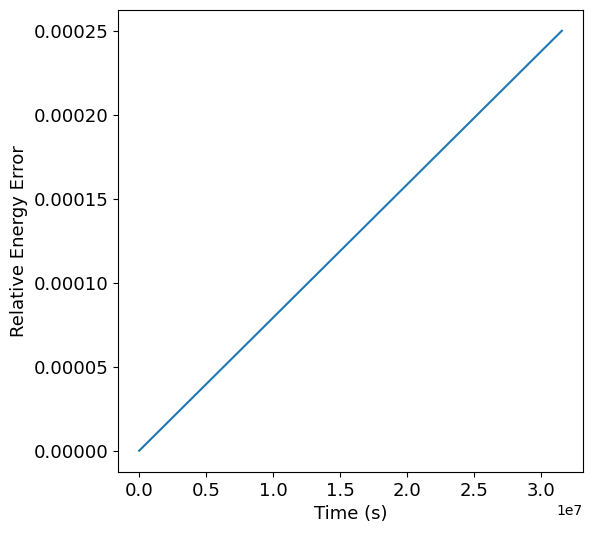

In [53]:
# method 2 evaluation 

position_op100 = history_orbital_period_dt100[:, :3]
velocity_op100 = history_orbital_period_dt100[:, 3:6]

magnitude_position_op100 = np.linalg.norm(position_op100, axis=1)
velocity_squared_op100 = np.sum(velocity_op100**2, axis=1)

total_energy_100 = 0.5*velocity_squared_op100 - physics.GRAVITATIONAL * physics.SUN_MASS / magnitude_position_op100

plt.figure(figsize=(6,6))

plt.plot(
    history_orbital_period_dt100[:,-1],
    (total_energy_100 - total_energy_100[0]) / np.linalg.norm(total_energy_100[0])
)

plt.xlabel("Time (s)", fontsize = 13)
plt.ylabel("Relative Energy Error", fontsize = 13)
plt.xticks(fontsize = 13)
plt.yticks(fontsize = 13) 

In [55]:
maximum_rel_error_100 = (total_energy_100[-1] - total_energy_100[0])/np.linalg.norm(total_energy_100[0])
print("maximum relative energy error: {}".format(maximum_rel_error_100))

maximum relative energy error: 0.0002501011096803597


dt = 1000

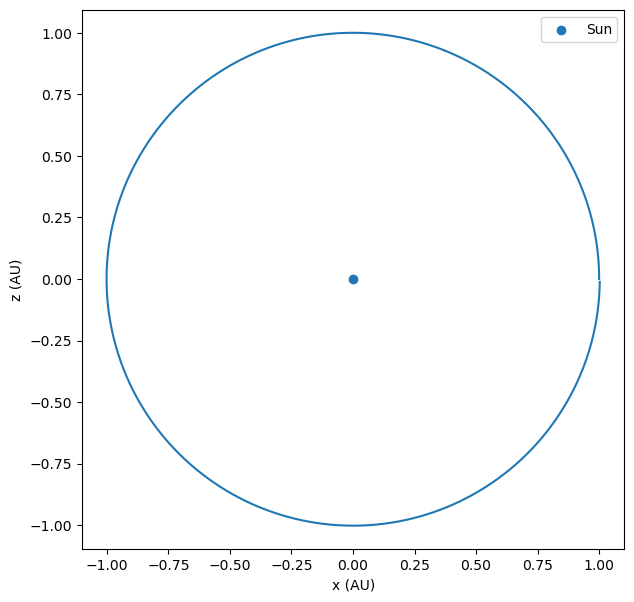

In [86]:
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.DT = 1000

physics.position_vector = np.array([physics.AU, 0.0, 0.0])
physics.velocity_vector = np.array([0, 0, orbit_speed])

state = np.concatenate((physics.position_vector, physics.velocity_vector, [0.0]))

history_orbital_period_dt1000 = physics.integrate_justg(orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt1000[:, 0] / physics.AU,
    history_orbital_period_dt1000[:, 2] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("z (AU)")
plt.axis("equal")
plt.legend()
plt.show()

In [88]:
# method 1 evaluation
initial_op1000 = history_orbital_period_dt1000[0]
final_op1000 = history_orbital_period_dt1000[-1]

pos_diff_op1000 = np.linalg.norm(final_op1000[:3] - initial_op1000[:3])

vel_diff_op1000 = np.linalg.norm(final_op1000[3:-1] - initial_op1000[3:-1]) 

print("position_difference relative to 1 AU: {}".format(pos_diff_op1000/physics.AU))
print("velocity difference: {}".format(vel_diff_op1000))

position_difference relative to 1 AU: 0.011874136338746719
velocity difference: 347.09565286128924


(array([-0.0005,  0.    ,  0.0005,  0.001 ,  0.0015,  0.002 ,  0.0025,
         0.003 ]),
 [Text(0, -0.0005, '−0.0005'),
  Text(0, 0.0, '0.0000'),
  Text(0, 0.0005, '0.0005'),
  Text(0, 0.001, '0.0010'),
  Text(0, 0.0015, '0.0015'),
  Text(0, 0.002, '0.0020'),
  Text(0, 0.0025, '0.0025'),
  Text(0, 0.003, '0.0030')])

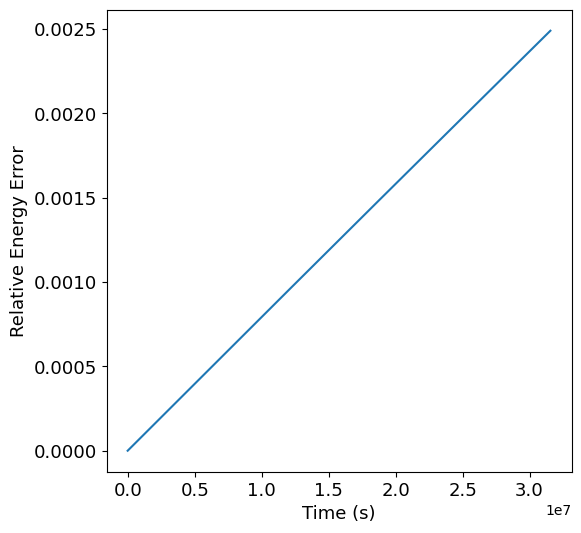

In [89]:
# method 2 evaluation 

position_op1000 = history_orbital_period_dt1000[:, :3]
velocity_op1000 = history_orbital_period_dt1000[:, 3:6]

magnitude_position_op1000 = np.linalg.norm(position_op1000, axis=1)
velocity_squared_op1000 = np.sum(velocity_op1000**2, axis=1)

total_energy_1000 = 0.5*velocity_squared_op1000 - physics.GRAVITATIONAL * physics.SUN_MASS / magnitude_position_op1000

plt.figure(figsize=(6,6))

plt.plot(
    history_orbital_period_dt1000[:,-1],
    (total_energy_1000 - total_energy_1000[0]) / np.linalg.norm(total_energy_1000[0])
)

plt.xlabel("Time (s)", fontsize = 13)
plt.ylabel("Relative Energy Error", fontsize = 13)
plt.xticks(fontsize = 13)
plt.yticks(fontsize = 13) 

In [90]:
maximum_rel_error_1000 = (total_energy_1000[-1] - total_energy_1000[0])/np.linalg.norm(total_energy_1000[0])
print("maximum relative energy error: {}".format(maximum_rel_error_1000))

maximum relative energy error: 0.0024898723544188304


In [85]:
physics.DT = 1000

physics.position_vector = np.array([
    physics.AU, 0.0, 0.0
])

physics.velocity_vector = np.array([
    0.0, 0.0, orbit_speed
])

print("position =", physics.position_vector)
print("velocity =", physics.velocity_vector)
print("gravity =", physics.a_due_to_gravity())

next_position, next_velocity = physics.update_state_justg()

print("next position =", next_position)
print("next velocity =", next_velocity)

position = [1.496e+11 0.000e+00 0.000e+00]
velocity = [    0.             0.         29788.89932051]
gravity = [-0.00593167 -0.         -0.        ]
next position = [1.49600000e+11 0.00000000e+00 2.97888993e+07]
next velocity = [-5.93167462e+00  0.00000000e+00  2.97888993e+04]
